# TP4 · Analyse de corpus
**Chapitre 2 · Partie 4 · Explorer un corpus** — Traitement Automatique du Langage Naturel

**Objectif :** décrire le corpus fil rouge (avis de restaurants) avec des chiffres et des graphiques :
fréquences, mots vides de domaine, loi de Zipf, n-grammes, collocations (PMI et LLR), concordances,
nuage de mots, puis rédiger une **courte synthèse**.

**Livrable :** ce notebook complété, avec une courte étude descriptive du corpus (partie 8) :
chiffres clés, courbe de Zipf, 10 collocations commentées.

| Partie | Contenu | Notions du cours |
|---|---|---|
| 0 | Mise en place : bibliothèques, corpus, `tokeniser()` | prétraitement (TP2) |
| 1 | Compter : tokens, types, hapax, TTR | TTR = V / N |
| 2 | Fréquences, mots vides généraux et de domaine | `Counter`, fréquence documentaire (df) |
| 3 | La loi de Zipf et la courbe en log-log | f × r ≈ C |
| 4 | Les n-grammes | N − n + 1 n-grammes |
| 5 | Les collocations : PMI, LLR, NLTK | PMI, G² |
| 6 | Les concordances (KWIC) | `nltk.Text.concordance()` |

### Comment travailler
- Exécutez les cellules **dans l'ordre** (Maj + Entrée).
- Les cellules marquées **`# À COMPLÉTER`** sont à compléter : remplacez les `None` par votre code.
- Après chaque exercice, une cellule **Vérification** vous dit si votre réponse est correcte (✅) ou ce qu'il faut corriger (❌).
- Les questions **✍️** demandent une réponse rédigée en une ou deux phrases.
- Sur Colab, tout est déjà installé. Sur votre machine : `pip install nltk matplotlib wordcloud`.

## Partie 0 · Mise en place

### 0.1 Les bibliothèques

In [1]:
import re                      # expressions régulières
import math                    # log2, log
from collections import Counter

import matplotlib.pyplot as plt
import nltk
nltk.download("stopwords", quiet=True)     # listes de mots vides
nltk.download("europarl_raw", quiet=True)  # grand corpus (partie ★ uniquement)

from nltk.corpus import stopwords
from nltk.text import Text
from nltk.collocations import BigramCollocationFinder, BigramAssocMeasures

print("Bibliothèques chargées.")

Bibliothèques chargées.


### 0.2 L'outil de vérification
Cette fonction vérifie vos réponses. Vous n'avez rien à modifier : exécutez simplement la cellule.

In [2]:
def verifier(nom, tests):
    """tests : liste de (fonction qui renvoie True/False, message si c'est faux)."""
    erreurs = []
    for test, message in tests:
        try:
            ok = test()
        except Exception:          # variable encore à None, mauvais type...
            ok = False
        if not ok:
            erreurs.append(message)
    if erreurs:
        print(f"❌ {nom} : à corriger")
        for m in erreurs:
            print("   -", m)
    else:
        print(f"✅ {nom} : tout est correct !")

### 0.3 Le corpus fil rouge
70 avis de restaurants, en français et en darija (écrite en lettres latines), avec leur sentiment.
On y retrouve les avis du cours (les dix premiers), plus d'autres avis avec du « bruit » : majuscules, émojis, URL, mention `@…`, lettres répétées (« Trooop »).

In [3]:
# Le corpus fil rouge : 70 avis de restaurants (français + quelques avis en darija)
# Chaque élément est un tuple (texte de l'avis, sentiment)
CORPUS = [
    ('Service rapide et personnel souriant, je recommande ce restaurant.', 'positif'),
    ('Le tajine au poulet était délicieux, service rapide.', 'positif'),
    ('Très bon rapport qualité prix, le couscous était parfait.', 'positif'),
    ('Service lent, le plat était froid. Je ne recommande pas.', 'négatif'),
    ('Le tajine au poulet est excellent et pas cher.', 'positif'),
    ('Très bon accueil, service rapide, je recommande.', 'positif'),
    ('Le couscous était froid et le service lent.', 'négatif'),
    ('Rapport qualité prix correct, mais le service est lent.', 'négatif'),
    ('Personnel souriant, tajine au poulet délicieux, très bon moment.', 'positif'),
    ('Pas cher, très bon, je recommande ce restaurant à Rabat.', 'positif'),
    ('Trooop bon !!! Le meilleur couscous de Casablanca 😍', 'positif'),
    ("Attente beaucoup trop longue, plus d'une heure pour un tajine froid.", 'négatif'),
    ('Cadre agréable, terrasse ensoleillée et service rapide.', 'positif'),
    ('Les prix sont trop élevés pour des portions aussi petites.', 'négatif'),
    ("Le thé à la menthe est excellent, l'accueil chaleureux.", 'positif'),
    ('Service lent et serveur désagréable, je ne reviendrai pas.', 'négatif'),
    ('Très bon tajine au poulet aux olives, je recommande vivement.', 'positif'),
    ('La pastilla au poulet était sèche et pas assez chaude.', 'négatif'),
    ('Rapport qualité prix imbattable, personnel souriant et attentionné.', 'positif'),
    ('Plat froid, service lent, prix élevés : une vraie déception.', 'négatif'),
    ('Le couscous royal est généreux et le service rapide.', 'positif'),
    ('Réservation perdue, attente interminable, accueil froid.', 'négatif'),
    ('Très bon restaurant, la terrasse est agréable le soir.', 'positif'),
    ('Le tajine de viande était trop salé et la viande dure.', 'négatif'),
    ('Accueil chaleureux, thé à la menthe offert, merci !', 'positif'),
    ('Les portions sont petites mais le goût est excellent.', 'positif'),
    ('Toilettes sales et salle bruyante, je ne recommande pas ce restaurant.', 'négatif'),
    ('Très bon rapport qualité prix, le personnel est souriant.', 'positif'),
    ('Service rapide le midi, parfait pour une pause déjeuner.', 'positif'),
    ('Le serveur a oublié notre commande, attente très longue.', 'négatif'),
    ('La harira est délicieuse et pas chère, je recommande.', 'positif'),
    ('Plats trop gras et service lent, dommage.', 'négatif'),
    ('Le meilleur tajine au poulet de Marrakech, rien à dire.', 'positif'),
    ('Prix élevés, musique trop forte, service lent.', 'négatif'),
    ('Très bon accueil et cadre magnifique, on reviendra.', 'positif'),
    ('Le couscous aux sept légumes était fade et froid.', 'négatif'),
    ('Pas cher et copieux, très bon rapport qualité prix.', 'positif'),
    ('Commande en ligne sur https://resto-exemple.ma : livraison rapide et plat chaud.', 'positif'),
    ('Livraison en retard et plat froid, je ne commanderai plus.', 'négatif'),
    ('@chef_rabat bravo pour le tajine au poulet, un régal !', 'positif'),
    ('Le personnel est souriant mais le service est lent.', 'négatif'),
    ('Très bon thé à la menthe et pâtisseries délicieuses.', 'positif'),
    ('Salle sale, nappes tachées, une mauvaise expérience.', 'négatif'),
    ('Service rapide, plats chauds et personnel souriant.', 'positif'),
    ("Trop cher pour ce que c'est, je ne recommande pas.", 'négatif'),
    ('La terrasse est agréable et le service rapide, très bon moment.', 'positif'),
    ("Le poisson n'était pas frais, très déçu.", 'négatif'),
    ('Tajine au poulet et citron confit : un délice, je recommande.', 'positif'),
    ('Accueil froid et attente longue avant de commander.', 'négatif'),
    ('Très bon couscous le vendredi, ambiance familiale.', 'positif'),
    ('Les frites étaient froides et le burger sec.', 'négatif'),
    ('Rapport qualité prix excellent, je recommande ce restaurant à tous.', 'positif'),
    ('Service lent, serveurs débordés, prix élevés.', 'négatif'),
    ('Cuisine marocaine authentique, tajine au poulet parfait.', 'positif'),
    ('Pas de climatisation en plein été, salle trop chaude.', 'négatif'),
    ('Très bon accueil, plats copieux et pas chers.', 'positif'),
    ("Le plat est arrivé froid après quarante minutes d'attente.", 'négatif'),
    ('Personnel souriant et service rapide, rien à redire.', 'positif'),
    ('Viande trop cuite et sauce fade, je ne reviendrai pas.', 'négatif'),
    ('Le couscous était délicieux et le thé à la menthe parfait.', 'positif'),
    ('lmakla bnina bzaf w service rapide, nsah bih', 'positif'),
    ('tajine dial djaj bnin bzaf, prix mzyan', 'positif'),
    ('service bti2 bzaf w lmakla barda, ma nsahch', 'négatif'),
    ('lmakla bnina walakin ghalya chwiya', 'négatif'),
    ('couscous bnin bzaf, nsah bih, service mzyan', 'positif'),
    ('tsennina sa3a kamla, service bti2 w lmakla barda', 'négatif'),
    ('staff drif bzaf w lmakla bnina, nsah bih', 'positif'),
    ('ghali bzaf w lmakla ma bninach', 'négatif'),
    ('Très bon restaurant, service rapide et plats délicieux.', 'positif'),
    ('Le tajine était froid et le service lent, très déçu.', 'négatif'),
]

avis = [texte for texte, sentiment in CORPUS]            # les textes seuls
sentiments = [sentiment for texte, sentiment in CORPUS]  # les étiquettes seules

print(len(avis), "avis :", sentiments.count("positif"), "positifs et",
      sentiments.count("négatif"), "négatifs")
print("Exemple :", avis[10])

70 avis : 39 positifs et 31 négatifs
Exemple : Trooop bon !!! Le meilleur couscous de Casablanca 😍


### 0.4 Prétraiter et tokeniser
`preprocess()` reprend en version courte le nettoyage du TP2 ; `tokeniser()` découpe en mots avec la regex `\w+`
(lettres, accents compris, et chiffres). Si vous avez votre propre `preprocess()` du TP2, vous pouvez la coller ici.

In [4]:
def preprocess(texte):
    """Nettoyage simple (version courte du TP2)."""
    texte = texte.lower()                          # 1. minuscules
    texte = re.sub(r"https?://\S+", " ", texte)    # 2. retirer les URL
    texte = re.sub(r"@\w+", " ", texte)            # 3. retirer les mentions @...
    texte = re.sub(r"(\w)\1{2,}", r"\1", texte)    # 4. « trooop » -> « trop »
    return texte

def tokeniser(texte):
    """Liste des mots en minuscules, sans ponctuation ni émojis."""
    return re.findall(r"\w+", preprocess(texte))

print(tokeniser("Trooop bon !!! Le meilleur couscous 😍 https://x.ma @chef"))
print(tokeniser(avis[3]))

['trop', 'bon', 'le', 'meilleur', 'couscous']
['service', 'lent', 'le', 'plat', 'était', 'froid', 'je', 'ne', 'recommande', 'pas']


> 💡 Remarque : « n'était » donne deux tokens, `n` et `était`. La négation `n` est donc conservée comme un mot.

## Partie 1 · Compter : tokens, types, hapax, TTR

**Rappel du cours.**

| Mesure | Définition |
|---|---|
| Tokens (N) | toutes les occurrences de mots |
| Types (V) | les mots différents |
| Hapax | les types vus une seule fois |
| TTR | V / N : la richesse du vocabulaire (entre 0 et 1) |

**Exemple** sur la phrase du cours : exécutez la cellule et vérifiez les chiffres à la main.

In [5]:
phrase = "le chat voit le chien . le chien dort ."
mots = [t for t in phrase.split() if t != "."]
frequences = Counter(mots)                  # compte chaque mot

print("tokens N :", len(mots))
print("types  V :", len(frequences))
print("hapax    :", [m for m, f in frequences.items() if f == 1])
print("TTR      :", round(len(frequences) / len(mots), 3))

tokens N : 8
types  V : 5
hapax    : ['chat', 'voit', 'dort']
TTR      : 0.625


### Exercice 1 · Les chiffres du corpus
1. `docs` : une liste qui contient, pour chaque avis, **la liste de ses tokens** (utilisez `tokeniser`).
2. `tokens` : **tous** les tokens du corpus dans une seule liste (on « aplatit » `docs`).
3. `freq` : le `Counter` des tokens.
4. `N`, `V`, `hapax` (liste des mots de fréquence 1) et `ttr`.

> 💡 Aplatir une liste de listes : `[x for sous_liste in liste for x in sous_liste]`

In [6]:
docs = [tokeniser(a) for a in avis]                 # liste de listes de tokens
tokens = [t for doc in docs for t in doc]           # on aplatit docs
freq = Counter(tokens)                              # Counter des tokens

N = len(tokens)                                     # nombre de tokens
V = len(freq)                                       # nombre de types
hapax = [m for m, c in freq.items() if c == 1]      # mots vus une seule fois
ttr = V / N                                         # richesse du vocabulaire

print("N =", N, "| V =", V, "| hapax =", None if hapax is None else len(hapax), "| TTR =", ttr)

N = 605 | V = 197 | hapax = 116 | TTR = 0.3256198347107438


In [7]:
verifier("Exercice 1", [
    (lambda: len(docs) == 70, "docs doit contenir 70 listes (une par avis)"),
    (lambda: docs[3] == tokeniser(avis[3]), "docs[3] doit être tokeniser(avis[3])"),
    (lambda: N == 605, "N doit valoir 605 (nombre total de tokens)"),
    (lambda: V == 197, "V doit valoir 197 (nombre de types)"),
    (lambda: len(hapax) == 116, "il doit y avoir 116 hapax"),
    (lambda: abs(ttr - V / N) < 1e-9, "ttr doit valoir V / N"),
])

✅ Exercice 1 : tout est correct !


**Question 1.** Que vaut le TTR ? Plus de la moitié des types sont des hapax : est-ce surprenant ?

✍️ **Votre réponse :** Le TTR vaut 197 / 605 ≈ **0,33** : un token sur trois seulement est un mot nouveau. Que 116 types sur 197 (59 %) soient des hapax n'est **pas surprenant** : c'est typique des textes réels (loi de Zipf). Quelques mots outils reviennent sans cesse, tandis que la plupart des mots (plats, adjectifs, fautes, darija, URL…) n'apparaissent qu'une fois. Sur un corpus de 605 tokens seulement, la part des hapax est encore plus élevée.

### Exercice 2 · Le TTR dépend de la longueur du texte
Calculez le TTR des **100, 200, 400 premiers tokens**, puis de tout le corpus, et rangez les valeurs dans la liste `ttrs`.

> 💡 `tokens[:100]` donne les 100 premiers tokens ; `set(liste)` donne les éléments différents.

In [8]:
ttrs = []
for taille in [100, 200, 400, N]:
    extrait = tokens[:taille]
    ttr_extrait = len(set(extrait)) / len(extrait)     # types / tokens de l'extrait
    ttrs.append(ttr_extrait)
    print(f"{taille:4} tokens -> TTR = {ttr_extrait}")

 100 tokens -> TTR = 0.44
 200 tokens -> TTR = 0.42
 400 tokens -> TTR = 0.3475
 605 tokens -> TTR = 0.3256198347107438


In [9]:
verifier("Exercice 2", [
    (lambda: len(ttrs) == 4, "ttrs doit contenir 4 valeurs"),
    (lambda: abs(ttrs[0] - len(set(tokens[:100])) / 100) < 1e-9, "TTR des 100 premiers tokens incorrect"),
    (lambda: ttrs[0] > ttrs[1] > ttrs[2] > ttrs[3], "le TTR doit diminuer quand le texte s'allonge"),
])

✅ Exercice 2 : tout est correct !


**Question 2.** Pourquoi le TTR baisse-t-il quand le texte s'allonge ? Quelle précaution faut-il prendre pour comparer deux corpus ?

✍️ **Votre réponse :** Le TTR baisse parce que les mots fonctionnels et les mots du domaine se répètent, alors que les nouveaux mots deviennent de plus en plus rares : N augmente plus vite que V (0,44 sur 100 tokens → 0,33 sur 605). Pour comparer deux corpus, il faut donc les comparer **à taille égale** (mêmes N premiers tokens, TTR sur fenêtres de longueur fixe ou TTR moyen par segments), sinon le plus long paraît artificiellement moins riche.

## Partie 2 · Fréquences et mots vides

**Rappel.** `freq.most_common(k)` renvoie les k mots les plus fréquents sous forme de couples `(mot, fréquence)`.
La **fréquence relative** f / N permet de comparer des corpus de tailles différentes.

**Exemple :** affichage aligné avec les f-strings (`{mot:10}` réserve 10 caractères, `{x:.1%}` affiche un pourcentage).

In [10]:
for mot, f in Counter(["le", "chat", "le", "chien", "le"]).most_common():
    print(f"{mot:10} {f:2}  {f / 5:.1%}")

le          3  60.0%
chat        1  20.0%
chien       1  20.0%


### Exercice 3 · Les 15 mots les plus fréquents
Affichez les 15 mots les plus fréquents du corpus avec leur fréquence absolue et leur fréquence relative.

In [11]:
top15 = freq.most_common(15)    # les 15 couples (mot, fréquence) les plus fréquents
for mot, f in top15 or []:
    print(f"{mot:12} {f:3}  {f / N:.1%}")

le            31  5.1%
et            29  4.8%
service       24  4.0%
très          17  2.8%
bon           15  2.5%
je            13  2.1%
pas           13  2.1%
est           13  2.1%
rapide        12  2.0%
tajine        12  2.0%
prix          11  1.8%
recommande    10  1.7%
était         10  1.7%
lent          10  1.7%
froid         10  1.7%


In [12]:
verifier("Exercice 3", [
    (lambda: len(top15) == 15, "top15 doit contenir 15 couples"),
    (lambda: top15[0] == ("le", 31), "le mot le plus fréquent est « le » (31 fois)"),
    (lambda: top15[2][0] == "service", "le 3e mot doit être « service »"),
])

✅ Exercice 3 : tout est correct !


**Question 3.** Quels types de mots sont en tête ? Quel est le premier mot « plein » et que dit-il du corpus ?

✍️ **Votre réponse :** En tête, on trouve surtout des **mots vides** : « le » (31), « et » (29), puis « je », « est », « était ». Le premier mot « plein » est **« service »** (24 occurrences, 4 %) : il révèle que le corpus parle avant tout de la qualité du service (rapide / lent), puis du tajine, du prix et de la recommandation. Le domaine (restaurants) et le genre (avis) se lisent donc dans ce mot dès la 3ᵉ place.

### Exercice 4 · Retirer les mots vides généraux
La liste française de NLTK contient 157 mots vides… dont **la négation** (`ne`, `pas`, `n`). Pour des avis, il faut la **garder** : elle porte le sentiment (« je ne recommande pas »).

1. `mots_vides` : l'ensemble des mots vides de NLTK **moins** `{"ne", "pas", "n"}`.
2. `tokens_pleins` : les tokens qui ne sont pas des mots vides.
3. `taux` : la part des tokens retirés (entre 0 et 1).
4. `freq_pleins` : le `Counter` de `tokens_pleins`.

> 💡 Différence de deux ensembles : `A - B`. Test d'appartenance : `mot not in A` (rapide sur un `set`).

In [13]:
liste_nltk = stopwords.words("french")
print(len(liste_nltk), "mots vides, par exemple :", liste_nltk[:12])
print("« pas » est dans la liste ?", "pas" in liste_nltk)

157 mots vides, par exemple : ['au', 'aux', 'avec', 'ce', 'ces', 'dans', 'de', 'des', 'du', 'elle', 'en', 'et']
« pas » est dans la liste ? True


In [14]:
negation = {"ne", "pas", "n"}
mots_vides = set(liste_nltk) - negation                       # NLTK moins la négation
tokens_pleins = [t for t in tokens if t not in mots_vides]    # tokens « pleins »
taux = 1 - len(tokens_pleins) / N                             # part des tokens retirés
freq_pleins = Counter(tokens_pleins)

print("Tokens retirés :", taux)
print(freq_pleins.most_common(10) if freq_pleins else None)

Tokens retirés : 0.28099173553719003
[('service', 24), ('très', 17), ('bon', 15), ('pas', 13), ('rapide', 12), ('tajine', 12), ('prix', 11), ('recommande', 10), ('lent', 10), ('froid', 10)]


In [15]:
verifier("Exercice 4", [
    (lambda: isinstance(mots_vides, set), "mots_vides doit être un set"),
    (lambda: "pas" not in mots_vides and "ne" not in mots_vides, "la négation (ne, pas, n) doit être gardée"),
    (lambda: "le" in mots_vides, "« le » doit rester un mot vide"),
    (lambda: len(tokens_pleins) == 435, "tokens_pleins doit contenir 435 tokens"),
    (lambda: abs(taux - (1 - 435 / 605)) < 1e-9, "taux = 1 - len(tokens_pleins) / N"),
    (lambda: freq_pleins.most_common(1)[0][0] == "service", "après filtrage, le 1er mot est « service »"),
])

✅ Exercice 4 : tout est correct !


**Question 4.** Quelle part du texte les mots vides représentent-ils ? Qu'est-ce que cela confirme ?

✍️ **Votre réponse :** Les mots vides retirés représentent environ **28 %** des tokens (605 → 435), alors qu'ils ne forment qu'une petite partie du vocabulaire. Cela confirme que le texte est dominé par quelques mots grammaticaux très fréquents mais peu informatifs, et qu'il faut les filtrer avant d'analyser le contenu. On a toutefois **gardé la négation** (ne, pas, n) car elle change le sens de l'avis.

### Exercice 5 · Les mots vides de domaine
Un **mot vide de domaine** apparaît dans une grande partie des documents **de ce corpus** : il ne permet plus de les distinguer.
On le repère par sa **fréquence documentaire** df = nombre d'avis qui contiennent le mot (au moins une fois).

**Exemple** sur trois mini-documents : `set(doc)` compte chaque mot une seule fois par document.

In [16]:
mini = [["le", "service", "rapide"], ["le", "service", "service", "lent"], ["le", "tajine"]]
df_mini = Counter(mot for doc in mini for mot in set(doc))
print(df_mini)      # « service » : présent dans 2 documents (même s'il apparaît 3 fois)

Counter({'le': 3, 'service': 2, 'rapide': 1, 'lent': 1, 'tajine': 1})


1. `df` : la fréquence documentaire de chaque mot du corpus.
2. `candidats` : les mots présents dans **au moins 15 %** des avis **et** qui ne sont pas dans `mots_vides`, du plus au moins fréquent.
3. Choisissez ensuite `mots_vides_domaine` : les candidats qui ne portent **ni opinion ni négation**.

In [17]:
df = Counter(mot for doc in docs for mot in set(doc))    # une seule fois par avis
seuil = 0.15
candidats = [m for m, c in df.most_common()
             if c / len(docs) >= seuil and m not in mots_vides]   # du plus au moins fréquent

for mot in candidats or []:
    print(f"{mot:10} présent dans {df[mot]:2} avis sur {len(docs)} ({df[mot] / len(docs):.0%})")

mots_vides_domaine = {"service", "tajine", "prix"}   # choisis parmi les candidats : ni opinion, ni négation

service    présent dans 24 avis sur 70 (34%)
très       présent dans 17 avis sur 70 (24%)
bon        présent dans 15 avis sur 70 (21%)
pas        présent dans 13 avis sur 70 (19%)
rapide     présent dans 12 avis sur 70 (17%)
tajine     présent dans 12 avis sur 70 (17%)
prix       présent dans 11 avis sur 70 (16%)


In [18]:
verifier("Exercice 5", [
    (lambda: df["service"] == 24, "df['service'] doit valoir 24"),
    (lambda: df["le"] == 26, "df['le'] doit valoir 26 (et non 31 : on compte une fois par avis)"),
    (lambda: candidats[0] == "service", "le premier candidat doit être « service »"),
    (lambda: "le" not in candidats, "les mots vides généraux ne sont pas des candidats"),
    (lambda: "service" in mots_vides_domaine, "« service » est un mot vide de domaine"),
    (lambda: not ({"bon", "rapide", "pas", "très"} & mots_vides_domaine), "ne retirez pas les mots d'opinion ni la négation"),
])

✅ Exercice 5 : tout est correct !


**Question 5.** Pourquoi ne faut-il pas retirer « bon », « rapide » ou « pas », alors qu'ils sont aussi très fréquents ?

✍️ **Votre réponse :** Un mot vide de domaine est présent partout et ne distingue plus les documents (« service », « tajine », « prix » : simples sujets de discussion). À l'inverse, « bon », « rapide » portent **l'opinion**, donc le sentiment (positif / négatif), et « pas » **inverse** le sens (« je ne recommande pas »). Les retirer détruirait justement l'information utile pour une analyse de sentiment ; « très » intensifie l'opinion, on le conserve aussi.

## Partie 3 · La loi de Zipf

**Rappel.** Si l'on classe les mots du plus fréquent au moins fréquent, la fréquence f d'un mot est à peu près inversement proportionnelle à son rang r :
**f × r ≈ C**. En échelle log-log, log f = log C − log r : une **droite de pente −1**.

**Exemple :** `enumerate(liste, start=1)` numérote les éléments à partir de 1, ce qui donne directement le rang.

In [19]:
for r, (mot, f) in enumerate([("le", 8), ("chat", 4), ("chien", 3)], start=1):
    print(r, mot, f, "-> r × f =", r * f)

1 le 8 -> r × f = 8
2 chat 4 -> r × f = 8
3 chien 3 -> r × f = 9


### Exercice 6 · Le tableau rang × fréquence
Pour les rangs 1, 2, 3, 5, 10, 20, 50 et 100, affichez le mot, sa fréquence et le produit r × f.
Rangez les produits dans le dictionnaire `produits` (clé : rang, valeur : r × f).

In [20]:
classement = freq.most_common()      # tous les mots, du + au - fréquent
produits = {}
for r, (mot, f) in enumerate(classement, start=1):
    if r in (1, 2, 3, 5, 10, 20, 50, 100):
        produits[r] = r * f
        print(f"{r:4}  {mot:12} {f:4}  {produits[r]}")

   1  le             31  31
   2  et             29  58
   3  service        24  72
   5  bon            15  75
  10  tajine         12  120
  20  couscous        8  160
  50  terrasse        3  150
 100  déception       1  100


In [21]:
verifier("Exercice 6", [
    (lambda: sorted(produits) == [1, 2, 3, 5, 10, 20, 50, 100], "il faut les 8 rangs demandés"),
    (lambda: produits[1] == 31 and produits[2] == 58, "r × f : 31 au rang 1, 58 au rang 2"),
])

✅ Exercice 6 : tout est correct !


### Exercice 7 · La courbe de Zipf en log-log
Tracez les fréquences en fonction du rang avec `plt.loglog`, puis la droite théorique **f = C / r** avec C = f₁ (la fréquence du mot n° 1).
Enregistrez l'image sous `zipf_avis.png`.

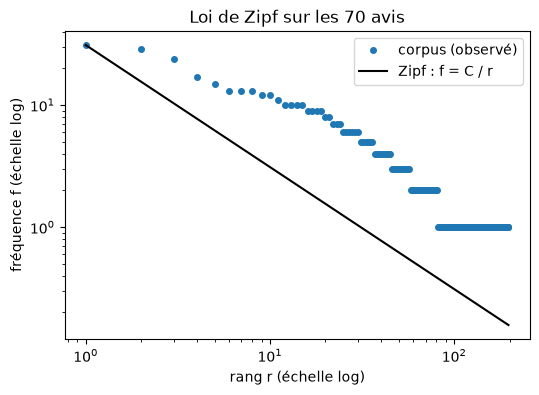

In [22]:
f = sorted(freq.values(), reverse=True)     # fréquences triées, de la plus grande à la plus petite
rangs = list(range(1, len(f) + 1))          # 1, 2, ..., V
zipf = [f[0] / r for r in rangs]            # droite théorique f = C / r avec C = f1

plt.figure(figsize=(6, 4))
plt.loglog(rangs, f, "o", markersize=4, label="corpus (observé)")
plt.loglog(rangs, zipf, "-", color="black", label="Zipf : f = C / r")
plt.legend()
plt.xlabel("rang r (échelle log)")
plt.ylabel("fréquence f (échelle log)")
plt.title("Loi de Zipf sur les 70 avis")
plt.savefig("zipf_avis.png", dpi=150, bbox_inches="tight")
plt.show()

In [23]:
verifier("Exercice 7", [
    (lambda: list(f[:3]) == [31, 29, 24], "f doit commencer par 31, 29, 24"),
    (lambda: len(f) == V and list(rangs)[-1] == V, "il faut un rang par type (1 à V)"),
    (lambda: abs(zipf[9] - 3.1) < 1e-9, "zipf[9] doit valoir f[0] / 10 = 3,1"),
])

✅ Exercice 7 : tout est correct !


**Question 6.** Les points suivent-ils la droite ? Que représentent les « marches » horizontales en bas à droite ?

✍️ **Votre réponse :** Globalement oui : le nuage descend bien en diagonale (quelques mots très fréquents en haut à gauche, une longue traîne de mots rares), mais il reste **au-dessus** de la droite f = C/r et décroît plus lentement que la pente −1 (r × f passe de 31 à 160 entre les rangs 1 et 20). C'est normal pour un petit corpus : le mot n° 1 (« le », 31) n'est pas beaucoup plus fréquent que les suivants (« et » 29, « service » 24). Les « marches » horizontales en bas à droite correspondent aux **nombreux mots qui ont exactement la même fréquence** (surtout les 116 hapax de fréquence 1, puis ceux de fréquence 2) : la fréquence ne prend que des valeurs entières, donc beaucoup de rangs consécutifs partagent la même valeur.

### Exercice 8 · La tête et la traîne
Calculez :
- `part_top10` : la part du texte (des tokens) couverte par les **10 mots les plus fréquents** ;
- `part_hapax` : la part des **types** qui sont des hapax.

In [24]:
part_top10 = sum(c for _, c in freq.most_common(10)) / N   # part des tokens couverte par le top 10
part_hapax = len(hapax) / V                                # part des types qui sont des hapax
print("Les 10 premiers mots couvrent", part_top10, "du texte")
print("Les hapax représentent", part_hapax, "des types")

Les 10 premiers mots couvrent 0.2958677685950413 du texte
Les hapax représentent 0.5888324873096447 des types


In [25]:
verifier("Exercice 8", [
    (lambda: abs(part_top10 - 179 / 605) < 1e-9, "part_top10 = somme des 10 plus grandes fréquences / N"),
    (lambda: abs(part_hapax - 116 / 197) < 1e-9, "part_hapax = nombre d'hapax / V"),
])

✅ Exercice 8 : tout est correct !


## Partie 4 · Les n-grammes

**Rappel.** Un n-gramme est une suite de n mots consécutifs. Avec une liste de N mots, il y a **N − n + 1** n-grammes.
On les calcule **avis par avis**, pour ne pas créer de bigramme « à cheval » entre deux avis.

**Exemple :** le découpage `liste[i:i+n]` prend n éléments à partir de la position i.

In [26]:
mots = ["le", "service", "est", "très", "rapide"]
print(mots[1:3])                                   # ['service', 'est']
print([tuple(mots[i:i+2]) for i in range(4)])      # les 4 bigrammes

['service', 'est']
[('le', 'service'), ('service', 'est'), ('est', 'très'), ('très', 'rapide')]


### Exercice 9 · La fonction `ngrammes`
Écrivez `ngrammes(tokens, n)` qui renvoie la **liste des n-grammes** (des tuples) de la liste `tokens`.

In [27]:
def ngrammes(tokens, n):
    return [tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1)]

print(ngrammes(["le", "service", "est", "très", "rapide"], 2))

[('le', 'service'), ('service', 'est'), ('est', 'très'), ('très', 'rapide')]


In [28]:
verifier("Exercice 9", [
    (lambda: ngrammes(["a", "b", "c"], 2) == [("a", "b"), ("b", "c")], "ngrammes(['a','b','c'], 2) doit donner [('a','b'), ('b','c')]"),
    (lambda: len(ngrammes(list("abcdefg"), 3)) == 5, "7 mots -> 7 - 3 + 1 = 5 trigrammes"),
    (lambda: ngrammes(["a"], 2) == [], "une liste trop courte donne une liste vide"),
])

✅ Exercice 9 : tout est correct !


### Exercice 10 · Les bigrammes et trigrammes fréquents
Comptez les bigrammes et les trigrammes **avis par avis** dans deux `Counter`, puis affichez les 10 bigrammes et les 5 trigrammes les plus fréquents.

In [29]:
bigrammes = Counter(b for doc in docs for b in ngrammes(doc, 2))     # avis par avis
trigrammes = Counter(t for doc in docs for t in ngrammes(doc, 3))

for b, n in (bigrammes.most_common(10) if bigrammes else []):
    print(f"{' '.join(b):24} {n}")
print()
for t3, n in trigrammes.most_common(5):
    print(f"{' '.join(t3):24} {n}")

très bon                 14
service rapide           11
au poulet                9
tajine au                8
service lent             8
je recommande            7
rapport qualité          6
qualité prix             6
je ne                    6
et le                    6

tajine au poulet         8
rapport qualité prix     6
et le service            4
thé à la                 4
à la menthe              4


In [30]:
verifier("Exercice 10", [
    (lambda: sum(bigrammes.values()) == N - len(docs), "il doit y avoir N - 70 = 535 bigrammes (calcul avis par avis)"),
    (lambda: bigrammes.most_common(1)[0] == (("très", "bon"), 14), "le bigramme le plus fréquent est « très bon » (14)"),
    (lambda: trigrammes[("tajine", "au", "poulet")] == 8, "« tajine au poulet » apparaît 8 fois"),
])

✅ Exercice 10 : tout est correct !


**Question 7.** Parmi les bigrammes fréquents, lesquels sont de vraies expressions ? Lesquels sont des suites banales ? Pourquoi la fréquence seule ne suffit-elle pas ?

✍️ **Votre réponse :** Les vraies expressions sont « très bon », « service rapide », « service lent », « rapport qualité (prix) », « je recommande », « tajine au poulet » : ce sont des unités de sens stables. Les suites banales sont « et le », « je ne » ou « est très », qui sont surtout des enchaînements grammaticaux (« et le service » est un trigramme banal). La fréquence seule ne suffit pas car des mots très fréquents (le, et, je) se retrouvent côte à côte par simple hasard : il faut comparer la fréquence observée à celle attendue si les mots étaient indépendants, ce que font la PMI et le LLR.

## Partie 5 · Les collocations : PMI et LLR

**Rappel.**
- **PMI** (force de l'association) : PMI(x, y) = log₂ ( P(x, y) / (P(x) × P(y)) ), avec P(x) = c(x) / N et P(x, y) = c(x, y) / N.
- **LLR** ou G² (fiabilité de l'association) : G² = 2 × Σ O × ln(O / E) sur les 4 cases du tableau de contingence.

**Exemple :** `math.log2` (log en base 2, pour la PMI) et `math.log` (log népérien ln, pour le LLR).

In [31]:
print(math.log2(8))             # 3.0 car 2³ = 8
print(round(math.log(2.718281828), 3))   # ≈ 1 car ln(e) = 1

3.0
1.0


### Exercice 11 · La PMI à la main, puis en Python
**✍️ D'abord sur papier :** N = 1 000 ; c(pas) = 20 ; c(cher) = 10 ; c(pas cher) = 8. Calculez P(pas), P(cher), P(pas, cher), le rapport observé / attendu, puis la PMI.

Écrivez ensuite `pmi(c_xy, c_x, c_y, N)` et vérifiez votre calcul.

**✍️ Calcul à la main (Exercice 11) :** N = 1 000 ; c(pas) = 20 ; c(cher) = 10 ; c(pas cher) = 8.

- P(pas) = 20 / 1 000 = **0,02** ; P(cher) = 10 / 1 000 = **0,01** ; P(pas, cher) = 8 / 1 000 = **0,008**
- Attendu si indépendants : 0,02 × 0,01 = 0,0002 → rapport observé / attendu = 0,008 / 0,0002 = **40**
- PMI(pas, cher) = log₂(40) ≈ **5,32** : « pas » et « cher » apparaissent ensemble 40 fois plus souvent que le hasard.

In [32]:
def pmi(c_xy, c_x, c_y, N):
    return math.log2((c_xy / N) / ((c_x / N) * (c_y / N)))

print("pas cher       :", pmi(8, 20, 10, 1000))
print("service rapide :", pmi(20, 100, 50, 10_000))   # exemple du cours

pas cher       : 5.321928094887363
service rapide : 5.321928094887363


In [33]:
verifier("Exercice 11", [
    (lambda: abs(pmi(8, 20, 10, 1000) - math.log2(40)) < 1e-9, "pmi(8, 20, 10, 1000) doit valoir log2(40) ≈ 5,32"),
    (lambda: abs(pmi(2, 2, 2, 15) - math.log2(7.5)) < 1e-9, "pmi(2, 2, 2, 15) doit valoir log2(7,5) ≈ 2,91 (exemple « thé fort »)"),
    (lambda: abs(pmi(1, 10, 10, 100)) < 1e-9, "deux mots indépendants donnent une PMI nulle"),
])

✅ Exercice 11 : tout est correct !


### Exercice 12 · La PMI sur le corpus
Calculez la PMI de tous les bigrammes vus **au moins 3 fois** (dictionnaire `scores_pmi`), puis affichez les 10 meilleurs.
Utilisez `freq` pour c(x) et c(y), `bigrammes` pour c(x, y) et `N` pour le nombre de tokens.

> 💡 Trier un dictionnaire par valeur décroissante : `sorted(d.items(), key=lambda kv: kv[1], reverse=True)`

In [34]:
seuil_freq = 3
scores_pmi = {(x, y): pmi(c, freq[x], freq[y], N)
              for (x, y), c in bigrammes.items() if c >= seuil_freq}
top_pmi = sorted(scores_pmi.items(), key=lambda kv: kv[1], reverse=True)[:10]

for (x, y), s in top_pmi or []:
    print(f"{x + ' ' + y:22} c={bigrammes[(x, y)]:2}  PMI={s:.2f}")

nsah bih               c= 3  PMI=7.66
rapport qualité        c= 6  PMI=6.66
lmakla bnina           c= 3  PMI=6.66
ce restaurant          c= 4  PMI=6.33
bzaf w                 c= 4  PMI=6.33
w lmakla               c= 4  PMI=6.33
thé à                  c= 4  PMI=6.24
au poulet              c= 9  PMI=6.07
la menthe              c= 4  PMI=6.07
personnel souriant     c= 5  PMI=5.95


In [35]:
verifier("Exercice 12", [
    (lambda: all(bigrammes[b] >= 3 for b in scores_pmi), "seuls les bigrammes vus au moins 3 fois sont gardés"),
    (lambda: len(scores_pmi) == 37, "il doit y avoir 37 bigrammes avec c >= 3"),
    (lambda: len(top_pmi) == 10 and top_pmi[0][1] >= top_pmi[-1][1], "top_pmi : 10 couples triés du meilleur au moins bon"),
    (lambda: scores_pmi[("service", "rapide")] > scores_pmi[("le", "service")], "« service rapide » doit battre « le service »"),
])

✅ Exercice 12 : tout est correct !


**Question 8.** Pourquoi faut-il un seuil de fréquence ? Que se passerait-il sans lui ?

✍️ **Votre réponse :** La PMI est très instable sur les couples rares : un bigramme vu une seule fois avec deux mots rares obtient mécaniquement un score énorme (probabilité jointe élevée par rapport au produit de deux très petites probabilités). Sans seuil, le haut du classement serait rempli de hapax et de paires accidentelles (fautes, URL, darija) sans valeur statistique. Un seuil (ici c ≥ 3) garantit que l'association est observée plusieurs fois.

### Exercice 13 · Le LLR (G²) pas à pas
Pour une paire (x, y), on remplit le tableau 2 × 2, on calcule l'attendu E de chaque case (total ligne × total colonne / N), puis
**G² = 2 × Σ O × ln(O / E)** (avec la convention 0 × ln 0 = 0).

| Case | O (observé) | E (attendu) |
|---|---|---|
| 11 | c(x, y) | c(x) × c(y) / N |
| 12 | c(x) − c(x, y) | c(x) × (N − c(y)) / N |
| 21 | c(y) − c(x, y) | (N − c(x)) × c(y) / N |
| 22 | N − c(x) − c(y) + c(x, y) | (N − c(x)) × (N − c(y)) / N |

**✍️ Vérifiez d'abord le cours :** pour « le chat » (c(le) = 3, c(chat) = 2, c(le, chat) = 2, N = 10), G² ≈ 6,19.

**✍️ Vérification du cours (Exercice 13) :** « le chat » avec c(le) = 3, c(chat) = 2, c(le, chat) = 2, N = 10.

| Case | O | E | O × ln(O / E) |
|---|---|---|---|
| 11 | 2 | 3 × 2 / 10 = 0,6 | 2 × ln(3,333) = 2,408 |
| 12 | 1 | 3 × 8 / 10 = 2,4 | 1 × ln(0,4167) = −0,875 |
| 21 | 0 | 7 × 2 / 10 = 1,4 | 0 (convention 0 × ln 0 = 0) |
| 22 | 7 | 7 × 8 / 10 = 5,6 | 7 × ln(1,25) = 1,562 |

G² = 2 × (2,408 − 0,875 + 0 + 1,562) = 2 × 3,095 ≈ **6,19** ✔

In [36]:
def llr(c_xy, c_x, c_y, N):
    O = [c_xy,
         c_x - c_xy,
         c_y - c_xy,
         N - c_x - c_y + c_xy]
    E = [c_x * c_y / N,
         c_x * (N - c_y) / N,
         (N - c_x) * c_y / N,
         (N - c_x) * (N - c_y) / N]
    return 2 * sum(o * math.log(o / e) for o, e in zip(O, E) if o > 0)

print("le chat   :", llr(2, 3, 2, 10))
print("chat noir :", llr(1, 2, 1, 10))

le chat   : 6.188963460994882
chat noir : 3.7290707455891843


In [37]:
verifier("Exercice 13", [
    (lambda: abs(llr(2, 3, 2, 10) - 6.19) < 0.01, "llr(2, 3, 2, 10) doit valoir 6,19 (exemple « le chat »)"),
    (lambda: abs(llr(1, 2, 1, 10) - 3.73) < 0.01, "llr(1, 2, 1, 10) doit valoir 3,73 (exemple « chat noir »)"),
    (lambda: abs(llr(1, 10, 10, 100)) < 1e-9, "deux mots indépendants donnent un LLR nul"),
])

✅ Exercice 13 : tout est correct !


Classez maintenant les bigrammes vus **au moins 2 fois** par LLR décroissant, et comparez avec la PMI.

In [38]:
scores_llr = {(x, y): llr(c, freq[x], freq[y], N)
              for (x, y), c in bigrammes.items() if c >= 2}
top_llr = sorted(scores_llr.items(), key=lambda kv: kv[1], reverse=True)[:10]

for (x, y), s in top_llr or []:
    print(f"{x + ' ' + y:22} c={bigrammes[(x, y)]:2}  LLR={s:6.2f}")

très bon               c=14  LLR=109.94
au poulet              c= 9  LLR= 93.61
service rapide         c=11  LLR= 70.02
rapport qualité        c= 6  LLR= 67.30
tajine au              c= 8  LLR= 63.56
qualité prix           c= 6  LLR= 52.14
je ne                  c= 6  LLR= 49.36
je recommande          c= 7  LLR= 46.25
service lent           c= 8  LLR= 44.65
personnel souriant     c= 5  LLR= 41.18


In [39]:
verifier("Exercice 13 (suite)", [
    (lambda: all(bigrammes[b] >= 2 for b in scores_llr), "seuls les bigrammes vus au moins 2 fois sont gardés"),
    (lambda: top_llr[0][0] == ("très", "bon"), "le meilleur LLR est « très bon »"),
    (lambda: len(top_llr) == 10, "top_llr doit contenir 10 couples"),
])

✅ Exercice 13 (suite) : tout est correct !


**Question 9.** Comparez les deux classements. Quelle mesure favorise les paires fréquentes ? Laquelle les paires exclusives ?

✍️ **Votre réponse :** La **PMI** mesure la *force* de l'association et favorise les paires **exclusives et plutôt rares** (« nsah bih », « lmakla bnina », « rapport qualité », « thé à ») : dès qu'un mot n'apparaît presque qu'avec l'autre, le score est élevé même avec 3 occurrences. Le **LLR** mesure la *fiabilité* (la preuve statistique) et favorise les paires **fréquentes** qui s'associent de façon significative (« très bon » 14, « au poulet », « service rapide », « service lent »). Le LLR est donc plus robuste pour repérer des collocations générales ; la PMI est utile pour repérer des expressions figées mais demande un seuil de fréquence.

### Exercice 14 · Les collocations avec NLTK
`BigramCollocationFinder` compte les unigrammes et les bigrammes à notre place.
On ajoute un jeton `<FIN>` après chaque avis pour ne pas créer de bigramme entre deux avis, puis on l'ignore avec `apply_word_filter`.

| Méthode | Rôle |
|---|---|
| `BigramCollocationFinder.from_words(liste)` | compte unigrammes et bigrammes |
| `finder.apply_word_filter(f)` | retire les bigrammes qui contiennent un mot tel que f(mot) est vrai |
| `finder.apply_freq_filter(k)` | garde les bigrammes vus au moins k fois |
| `finder.nbest(mesure, k)` | les k meilleurs bigrammes |
| `finder.score_ngrams(mesure)` | tous les bigrammes avec leur score |

In [40]:
tokens_fin = [t for doc in docs for t in doc + ["<FIN>"]]    # "<FIN>" après chaque avis
mesures = BigramAssocMeasures()
finder = BigramCollocationFinder.from_words(tokens_fin)
finder.apply_word_filter(lambda mot: mot == "<FIN>")         # on ignore les bigrammes avec <FIN>
finder.apply_freq_filter(3)                                  # seuil de fréquence 3

nltk_pmi = finder.nbest(mesures.pmi, 10)                     # 10 meilleurs selon la PMI
nltk_llr = finder.nbest(mesures.likelihood_ratio, 10)        # 10 meilleurs selon le LLR
print("PMI :", nltk_pmi)
print("LLR :", nltk_llr)

PMI : [('nsah', 'bih'), ('lmakla', 'bnina'), ('rapport', 'qualité'), ('bzaf', 'w'), ('ce', 'restaurant'), ('w', 'lmakla'), ('thé', 'à'), ('au', 'poulet'), ('la', 'menthe'), ('personnel', 'souriant')]
LLR : [('très', 'bon'), ('au', 'poulet'), ('service', 'rapide'), ('rapport', 'qualité'), ('tajine', 'au'), ('qualité', 'prix'), ('je', 'ne'), ('je', 'recommande'), ('service', 'lent'), ('personnel', 'souriant')]


In [41]:
verifier("Exercice 14", [
    (lambda: tokens_fin.count("<FIN>") == 70, "tokens_fin doit contenir un <FIN> par avis"),
    (lambda: len(nltk_pmi) == 10 and len(nltk_llr) == 10, "il faut 10 bigrammes par mesure"),
    (lambda: all("<FIN>" not in b for b in nltk_pmi + nltk_llr), "aucun bigramme ne doit contenir <FIN>"),
    (lambda: nltk_llr[0] == ("très", "bon"), "le meilleur LLR selon NLTK est « très bon »"),
])

✅ Exercice 14 : tout est correct !


**Question 10.** Les listes de NLTK ressemblent-elles aux vôtres ? D'où peuvent venir les petites différences de scores ?

✍️ **Votre réponse :** Oui : on retrouve **les mêmes 10 bigrammes** que dans nos classements (PMI : « nsah bih », « rapport qualité », « lmakla bnina »… ; LLR : « très bon », « au poulet », « service rapide »…), avec le même ordre pour le LLR et un ordre légèrement différent pour quelques paires quasi à égalité en PMI (« rapport qualité » / « lmakla bnina »). Les petits écarts de scores (ex. PMI de « nsah bih » : 7,81 chez NLTK contre 7,66 chez nous ; LLR de « très bon » : 113,0 contre 109,9) viennent du **total N utilisé** : le finder compte les 70 jetons `<FIN>` en plus des 605 tokens (N = 675), ce qui modifie les probabilités P(x), P(x, y) et le tableau de contingence.

## Partie 6 · Les concordances (KWIC)

**Rappel.** Une concordance affiche toutes les occurrences d'un mot, **alignées au centre**, avec leur contexte gauche et droit.

**Exemple :** `re.finditer` donne chaque occurrence avec sa position (`m.start()`, `m.end()`) ; `\b` impose un mot entier ; `{texte:>20}` aligne à droite sur 20 caractères.

In [42]:
texte = "Service rapide, mais le service du soir est lent."
for m in re.finditer(r"\bservice\b", texte, flags=re.IGNORECASE):
    print(m.start(), m.end(), repr(m.group()), "| à gauche :", repr(texte[:m.start()][-12:]))
print(f"[{'droite':>10}]  [{'gauche':<10}]")

0 7 'Service' | à gauche : ''
24 31 'service' | à gauche : 'de, mais le '
[    droite]  [gauche    ]


### Exercice 15 · Votre propre concordance
Écrivez `concordance(textes, mot, largeur=30)` qui, pour chaque avis, trouve toutes les occurrences du **mot entier** (sans tenir compte des majuscules)
et **renvoie la liste des lignes** au format : `contexte gauche aligné à droite` + ` [mot] ` + `contexte droit`.

In [43]:
def concordance(textes, mot, largeur=30):
    lignes = []
    for texte in textes:
        for m in re.finditer(rf"\b{re.escape(mot)}\b", texte, flags=re.IGNORECASE):
            gauche = texte[max(0, m.start() - largeur):m.start()]    # au plus `largeur` caractères avant
            droite = texte[m.end():m.end() + largeur]                # au plus `largeur` caractères après
            lignes.append(f"{gauche:>{largeur}} [{m.group()}] {droite}")
    return lignes

for ligne in concordance(avis, "service")[:8]:
    print(ligne)

                               [Service]  rapide et personnel souriant,
ne au poulet était délicieux,  [service]  rapide.
                               [Service]  lent, le plat était froid. Je
            Très bon accueil,  [service]  rapide, je recommande.
Le couscous était froid et le  [service]  lent.
qualité prix correct, mais le  [service]  est lent.
able, terrasse ensoleillée et  [service]  rapide.
                               [Service]  lent et serveur désagréable, 


In [44]:
verifier("Exercice 15", [
    (lambda: len(concordance(avis, "service")) == 24, "« service » apparaît 24 fois dans les avis"),
    (lambda: len(concordance(["Le Service et les services"], "service")) == 1, "seul le mot entier compte (pas « services »)"),
    (lambda: concordance(["le service rapide"], "service", 5)[0] == "  le  [service]  rapi", "format : gauche aligné à droite, [mot], puis la droite"),
])

✅ Exercice 15 : tout est correct !


### Exercice 16 · Les concordances avec NLTK
`nltk.Text(liste_de_tokens)` crée un texte NLTK ; ses méthodes :
- `t.concordance(mot, width=79, lines=25)` **affiche** les lignes ;
- `t.concordance_list(mot, width=79, lines=25)` **renvoie** les lignes : chaque ligne a `.left` (mots à gauche), `.query` (le mot) et `.right` (mots à droite).

1. Affichez la concordance de « service » (largeur 60, 6 lignes).
2. Avec `concordance_list`, comptez le **premier mot à droite** de « service » (`droite_service`) puis de « pas » (`droite_pas`).

In [45]:
t = Text(tokens)                                    # un nltk.Text de tous les tokens
t.concordance("service", width=60, lines=6)         # affiche la concordance de « service »

res = t.concordance_list("service", width=79, lines=100)
droite_service = Counter(l.right[0] for l in res if l.right)     # 1er mot à droite de « service »
res_pas = t.concordance_list("pas", width=79, lines=100)
droite_pas = Counter(l.right[0] for l in res_pas if l.right)     # 1er mot à droite de « pas »
print(droite_service)
print(droite_pas)

Displaying 6 of 24 matches:
                          service rapide et personnel souri
au poulet était délicieux service rapide très bon rapport q
le couscous était parfait service lent le plat était froid 
pas cher très bon accueil service rapide je recommande le c
ouscous était froid et le service lent rapport qualité prix
lité prix correct mais le service est lent personnel souria
Counter({'rapide': 11, 'lent': 8, 'est': 2, 'bti2': 2, 'mzyan': 1})
Counter({'cher': 3, 'le': 2, 'très': 1, 'assez': 1, 'ce': 1, 'chère': 1, 'la': 1, 'frais': 1, 'de': 1, 'chers': 1})


In [46]:
verifier("Exercice 16", [
    (lambda: isinstance(t, Text), "t doit être un nltk.Text"),
    (lambda: len(res) == 24, "res doit contenir les 24 occurrences de « service »"),
    (lambda: droite_service["rapide"] == 11 and droite_service["lent"] == 8, "à droite de « service » : rapide 11 fois, lent 8 fois"),
    (lambda: droite_pas["cher"] == 3, "« pas cher » apparaît 3 fois"),
])

✅ Exercice 16 : tout est correct !


**Question 11.** Que révèle la concordance de « service » ? Et celle de « pas » : ce mot est-il toujours négatif ?

✍️ **Votre réponse :** La concordance de « service » montre qu'il est presque toujours suivi d'un **qualificatif d'opinion** : « rapide » (11 fois) ou « lent » (8 fois), donc un mot d'évaluation temporelle ; c'est le critère n° 1 des avis. Pour « pas », le premier mot à droite est « cher » (3 fois, « pas cher » = **positif**), mais aussi « le », « très », « assez », « frais » (« pas frais » = négatif) ou « pas recommander » : **« pas » n'est donc pas toujours négatif**, il inverse le sens du mot suivant. C'est la raison pour laquelle il ne faut pas le supprimer ni l'analyser isolément.

## Partie 8 · Synthèse : l'étude descriptive du corpus

### Exercice 18 · Les chiffres clés en une fonction
Écrivez `chiffres_cles(docs)` qui renvoie un **dictionnaire** avec : `nb_avis`, `N`, `V`, `TTR`, `hapax` (nombre) et `longueur_moyenne` (nombre moyen de tokens par avis).
La fonction doit marcher pour **n'importe quelle** liste de documents tokenisés (elle servira dans la partie ★).

In [47]:
def chiffres_cles(docs):
    toks = [t for doc in docs for t in doc]
    c = Counter(toks)
    n, v = len(toks), len(c)
    return {
        "nb_avis": len(docs),
        "N": n,
        "V": v,
        "TTR": v / n,
        "hapax": sum(1 for f in c.values() if f == 1),
        "longueur_moyenne": n / len(docs),
    }

for cle, valeur in chiffres_cles(docs).items():
    print(f"{cle:17} {valeur}")

nb_avis           70
N                 605
V                 197
TTR               0.3256198347107438
hapax             116
longueur_moyenne  8.642857142857142


In [48]:
verifier("Exercice 18", [
    (lambda: chiffres_cles(docs)["N"] == 605 and chiffres_cles(docs)["V"] == 197, "N = 605 et V = 197"),
    (lambda: chiffres_cles(docs)["hapax"] == 116, "116 hapax"),
    (lambda: abs(chiffres_cles(docs)["longueur_moyenne"] - 8.6) < 0.06, "longueur moyenne ≈ 8,6 tokens par avis"),
    (lambda: chiffres_cles([["a", "b"], ["a"]])["V"] == 2, "la fonction doit marcher sur d'autres documents"),
])

✅ Exercice 18 : tout est correct !


### La synthèse (livrable)
Rédigez, dans la cellule ci-dessous, une courte étude descriptive du corpus (10 à 15 lignes) en vous appuyant sur vos résultats :
1. **Chiffres clés** : nombre d'avis, N, V, TTR, hapax ; ce que cela dit du vocabulaire.
2. **Fréquences et Zipf** : les mots en tête, les mots vides de domaine retenus, la forme de la courbe (insérez `zipf_avis.png`).
3. **10 collocations commentées** : expression, mesure (PMI ou LLR), ce qu'elle dit des avis.
4. **Concordances** : ce que révèlent « service » et « pas ».
5. **Limites** : taille du corpus, darija, prétraitement.

✍️ **Ma synthèse :**

**1. Chiffres clés.** Le corpus compte **70 avis** (39 positifs, 31 négatifs), soit **N = 605 tokens** (8,6 tokens par avis en moyenne) pour **V = 197 types**. Le TTR vaut **0,33** et **116 types (59 %) sont des hapax** : le vocabulaire est assez répétitif (lexique de restaurant) avec une longue traîne de mots rares ; le corpus est petit, donc le TTR n'est comparable qu'à longueur égale.

**2. Fréquences et Zipf.** En tête : « le » (31), « et » (29), puis le premier mot plein **« service »** (24), « très », « bon », « pas », « rapide », « tajine », « prix ». Les mots vides généraux représentent 28 % des tokens ; on a conservé la négation (ne, pas, n). Les mots vides de domaine retenus sont **« service », « tajine », « prix »** (présents dans ≥ 15 % des avis, ni opinion ni négation). La courbe en log-log (`zipf_avis.png`) suit globalement une droite de pente −1 : les 10 premiers mots couvrent 30 % du texte, et les hapax forment des « marches » en bas à droite.

![Courbe de Zipf](zipf_avis.png)

**3. Dix collocations commentées.**
- **très bon** (LLR 109,9) : intensifieur + opinion, la marque de l'avis positif.
- **au poulet** (LLR 93,6) / **tajine au poulet** : le plat le plus cité.
- **service rapide** (LLR 70,0) : critère positif récurrent.
- **service lent** (LLR 44,7) : son pendant négatif.
- **rapport qualité (prix)** (PMI 6,66 ; LLR 67,3) : expression figée, collocation par excellence.
- **je recommande** (LLR 46,3) : formule de conclusion des avis positifs.
- **personnel souriant** (PMI 5,95 ; LLR 41,2) : critère d'accueil.
- **thé à la menthe** (PMI 6,24) : spécialité marocaine, unité lexicale figée.
- **nsah bih** (PMI 7,66, 3 occ.) : « je le recommande » en darija.
- **lmakla bnina** (PMI 6,66) : « la nourriture est bonne » en darija.

La PMI fait remonter les expressions exclusives (darija, « thé à »), le LLR les paires fréquentes et fiables (« très bon », « service rapide »).

**4. Concordances.** « service » est suivi de « rapide » (11/24) ou « lent » (8/24) : l'avis porte surtout sur la rapidité. « pas » est suivi de « cher » (3 fois, positif), mais aussi de mots comme « frais » : il inverse le sens du mot suivant et n'est donc pas toujours négatif.

**5. Limites.** Corpus **très petit** (70 avis, 605 tokens) : beaucoup de hapax, scores PMI instables, TTR peu fiable. Le mélange **français / darija** en lettres latines (orthographe non normalisée : « bnina », « bzaf », « bti2 ») fausse les fréquences et rend les listes de mots vides inadaptées. Le prétraitement est simple : `\w+` coupe « n'était » en `n` + `était` et ne gère pas la lemmatisation (« chère », « chers », « cher » sont trois types différents).